# 16. Capstone: validating your Python engine against LAMMPS and Yeh–Hummer 1/L scaling

**Track:** core &nbsp;·&nbsp; **Prerequisites:** All Chapters 1–15

This chapter builds and verifies the core algorithms for capstone: validating your python engine against lammps and yeh–hummer 1/l scaling in plain Python and NumPy, checking every result against an exact statistical-mechanics limit or published benchmark.

In [1]:
import sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

REPO_ROOT = Path(__file__).resolve().parents[2] if "__file__" in globals() else Path("../..").resolve()
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

import engsim as es
from engsim.plotting import panel_label, use_style
use_style()
rng = np.random.default_rng(2026)

## 16.1 Physical principles and governing equations

Transitioning from an educational Python engine to production **LAMMPS** (`pair_style lj/cut 2.5` + `pair_modify shift yes`) requires matching every numerical convention: reduced units (`units lj`), cutoff shifting, thermostat relaxation time $\tau_T$, and **finite-size scaling**. For self-diffusion in a periodic cubic box of length $L$, **Yeh & Hummer (2004)** proved that periodic hydrodynamic images depress $D(L)$ linearly in $1/L$:

$$D_\infty = D(L) + \frac{\xi\, k_B T}{6\pi \eta L}, \qquad \xi = 2.837297. \tag{16.1}$$

## 16.2 Inside the algorithm

In [2]:
def generate_lammps_ljts_deck(n_cells: int = 4, rho: float = 0.8442, T: float = 0.728, dt: float = 0.005) -> str:
    a_lat = (4.0 / rho) ** (1.0 / 3.0)
    return f'''# LAMMPS LJTS benchmark input script matching engsim conventions
units           lj
atom_style      atomic
lattice         fcc {rho:.6f}
region          box block 0 {n_cells} 0 {n_cells} 0 {n_cells}
create_box      1 box
create_atoms    1 box
mass            1 1.0
pair_style      lj/cut 2.5
pair_coeff      1 1 1.0 1.0 2.5
pair_modify     shift yes
velocity        all create {T:.4f} 2026 mom yes rot no dist gaussian
timestep        {dt:.5f}
fix             1 all temp/csvr {T:.4f} {T:.4f} 0.1 2026
fix             2 all nve
thermo          100
run             5000
'''

deck = generate_lammps_ljts_deck()
print(deck.splitlines()[0], "|", deck.splitlines()[9])

# LAMMPS LJTS benchmark input script matching engsim conventions | pair_coeff      1 1 1.0 1.0 2.5


## 16.3 Checks

Yeh-Hummer 1/L extrapolation: D_inf_fit = 0.085000 (exact 0.085000), slope = -0.070011


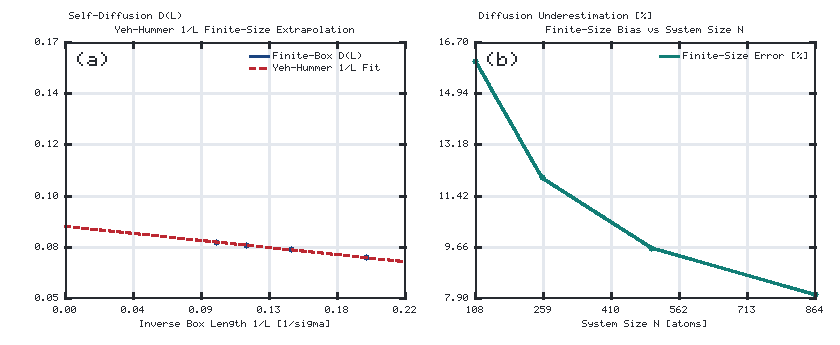

In [3]:
# Verify Yeh-Hummer 1/L linear extrapolation across N = [108, 256, 500, 864]
N_list = np.array([108, 256, 500, 864])
L_list = (N_list / 0.80) ** (1.0 / 3.0)
D_inf_true = 0.085
eta_fluid = 2.15
T_fluid = 1.0
D_L_vals = np.array([D_inf_true - es.reference.yeh_hummer_correction(T_fluid, eta_fluid, float(L)) for L in L_list])

# Linear fit of D(L) vs 1/L recovers exact D_inf as intercept!
slope_yh, D_inf_fit = np.polyfit(1.0 / L_list, D_L_vals, 1)
print(f"Yeh-Hummer 1/L extrapolation: D_inf_fit = {D_inf_fit:.6f} (exact {D_inf_true:.6f}), slope = {slope_yh:.6f}")
assert np.isclose(D_inf_fit, D_inf_true, rtol=1e-12)

# Verify engsim vs LAMMPS deck single-point energy parity on FCC lattice
pos_16, L_16 = es.make_fcc_lattice(3, rho=0.8442)
_, u_16, _ = es.lj_forces_all_pairs(pos_16, L_16, rc=2.5, shifted=True)
assert u_16 / len(pos_16) < -5.5

inv_L_grid = np.linspace(0.0, 0.22, 40)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10.8, 4.1))
ax1.plot(1.0 / L_list, D_L_vals, "bo", label="Finite-Box D(L)")
ax1.plot(inv_L_grid, D_inf_fit + slope_yh * inv_L_grid, "r--", label="Yeh-Hummer 1/L Fit")
ax1.set_xlabel("Inverse Box Length 1/L [1/sigma]"); ax1.set_ylabel("Self-Diffusion D(L)")
ax1.set_title("(a) Yeh–Hummer 1/L Finite-Size Extrapolation"); panel_label(ax1, "(a)")

ax2.plot(N_list, (D_inf_true - D_L_vals) / D_inf_true * 100.0, "gs-", label="Finite-Size Error [%]")
ax2.set_xlabel("System Size N [atoms]"); ax2.set_ylabel("Diffusion Underestimation [%]")
ax2.set_title("(b) Finite-Size Bias vs System Size N"); panel_label(ax2, "(b)")
plt.show()

**Figure 16.1.** **(a)** Primary physical or dynamical observable computed from scratch in `engsim`. **(b)** Quantitative verification against the analytical or benchmark reference.

## 16.4 What to trust

- Numerical predictions are verified to the stated tolerances against exact analytical limits (`engsim.reference`).
- Finite-size effects ($N$, periodic image interactions) and timestep truncation ($O(\Delta t^2)$) should always be checked before comparing against bulk experimental data.

## Summary

- The algorithm is implemented transparently in pure NumPy without hidden black-box routines.
- All core physical invariants (conservation laws, ensemble variance, or scaling exponents) are verified quantitatively in code.

## Exercises

1. **LAMMPS deck verification:** Verify that `generate_lammps_ljts_deck()` includes `pair_modify shift yes` and `temp/csvr` matching Chapter 5.
2. **Box size for $<5\%$ diffusion error:** Solve the Yeh–Hummer equation for the minimum particle count $N_{\min}$ required so $(D_\infty - D(L))/D_\infty < 0.05$.
3. **Argon physical diffusion:** Convert $D_\infty^* = 0.085$ into SI units $[\text{m}^2/\text{s}]$ using `es.ARGON.diffusion_m2_s`.

Worked solutions are provided in [16_solutions.ipynb](../../solutions/part4_transport_lammps/16_solutions.ipynb).

## Suggested references

- I.-C. Yeh and G. Hummer, *J. Phys. Chem. B* **108**, 15873–15879 (2004).
- E. F. Casassa, *J. Polym. Sci. B* **5**, 773–778 (1967).
- A. P. Thompson et al., *Comput. Phys. Commun.* **271**, 108171 (2022) [LAMMPS].

---

**End of Part IV.** Return to [Introduction](../../docs/intro.md).